## Netflix Visual Analytics

This notebook extracts, cleans, explores, and visualizes the provided Netflix catalog dataset using Python. Because the supplied dataset was a CSV rather than a ZIP archive, a ZIP copy was created to demonstrate the required extraction and renaming workflow.

# Import Libraries

The required libraries support file extraction, data processing, statistical exploration, and visualization.

In [1]:
# Work with file and folder paths
from pathlib import Path

# Extract the ZIP archive
import zipfile

# Process and analyze the Netflix dataset
import pandas as pd

# Create charts with Matplotlib's pyplot interface
import matplotlib.pyplot as plt

# Create statistical visualizations
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


# Prepare the Dataset
The source ZIP file, extraction folder, and renamed Netflix CSV file are defined using relative paths.

In [2]:
# Define the source ZIP file
source_zip = Path("netflix_data.zip")

# Define the extraction folder
extraction_folder = Path("extracted_data")

# Define the original CSV location after extraction
extracted_csv = extraction_folder / "netflix_data.csv"

# Define the required renamed CSV file
renamed_csv = Path("Netflix_shows_movies.csv")

# Display the paths
print(f"Source ZIP: {source_zip}")
print(f"Extraction folder: {extraction_folder}")
print(f"Extracted CSV: {extracted_csv}")
print(f"Renamed CSV: {renamed_csv}")

Source ZIP: netflix_data.zip
Extraction folder: extracted_data
Extracted CSV: extracted_data\netflix_data.csv
Renamed CSV: Netflix_shows_movies.csv


In [3]:
# Confirm that the source ZIP exists
if not source_zip.exists():
    raise FileNotFoundError(
        "netflix_data.zip was not found in the project folder."
    )
print("Source ZIP file found successfully.")

# Create the extraction folder if it does not already exist
extraction_folder.mkdir(
    parents=True,
    exist_ok=True
)
print("Extraction folder created successfully.")

# Open the ZIP archive and extract its contents
with zipfile.ZipFile(source_zip, "r") as archive:
    archive.extractall(extraction_folder)

print("Dataset extracted successfully.")

# Confirm that the expected CSV was extracted
if not extracted_csv.exists():
    raise FileNotFoundError(
        "netflix_data.csv was not found after extraction."
    )

print("Extracted CSV file found successfully.")

# Copy the extracted CSV using the required filename
renamed_csv.write_bytes(
    extracted_csv.read_bytes()
)

print("Dataset renamed successfully.")
print(f"Renamed file: {renamed_csv}")

# Confirm that the renamed dataset exists
if not renamed_csv.exists():
    raise FileNotFoundError(
        "Netflix_shows_movies.csv was not created."
    )

print("Renamed dataset found successfully.")

Source ZIP file found successfully.
Extraction folder created successfully.
Dataset extracted successfully.
Extracted CSV file found successfully.
Dataset renamed successfully.
Renamed file: Netflix_shows_movies.csv
Renamed dataset found successfully.


# Load the Dataset
The renamed Netflix dataset is loaded into a pandas DataFrame for cleaning, exploration, and visualization.

In [4]:
# Load the renamed Netflix dataset
try:
    netflix_data = pd.read_csv(renamed_csv)
    print("Netflix dataset loaded successfully.")
except FileNotFoundError:
    print("Netflix_shows_movies.csv could not be found.")
except pd.errors.EmptyDataError:
    print("Netflix_shows_movies.csv is empty.")
except pd.errors.ParserError:
    print("Netflix_shows_movies.csv could not be parsed correctly.")
except Exception as error:
    print(f"An unexpected error occurred: {error}")

print(f"Number of rows: {netflix_data.shape[0]:,}")
print(f"Number of columns: {netflix_data.shape[1]}")

Netflix dataset loaded successfully.
Number of rows: 6,234
Number of columns: 12


# Preview the Data
The first five records and column names are displayed to confirm the dataset structure.

In [5]:
# Display the first five rows
netflix_data.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


In [6]:
# Display the column names
print("Dataset columns:")

for column in netflix_data.columns:
    print(f"- {column}")

Dataset columns:
- show_id
- type
- title
- director
- cast
- country
- date_added
- release_year
- rating
- duration
- listed_in
- description


# Inspect and Clean the Data
The dataset's data types, missing values, and duplicate records are examined before analysis.

In [7]:
# Display the data type of each column
netflix_data.dtypes

show_id         int64
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

In [8]:
# Count missing values in every column
missing_values = netflix_data.isna().sum()
print("Missing values by column:")
print(missing_values)

Missing values by column:
show_id            0
type               0
title              0
director        1969
cast             570
country          476
date_added        11
release_year       0
rating            10
duration           0
listed_in          0
description        0
dtype: int64


# Clean Missing Text Values
Missing director, cast, country, and rating values are replaced with clear labels. The date column will be converted separately.

In [9]:
# Create a cleaned copy
netflix_clean = netflix_data.copy()

# Replace missing director values
netflix_clean["director"] = netflix_clean["director"].fillna("Unknown Director")

# Replace missing cast values
netflix_clean["cast"] = netflix_clean["cast"].fillna("Unknown Cast")

# Replace missing country values
netflix_clean["country"] = netflix_clean["country"].fillna("Unknown Country")

# Replace missing rating values
netflix_clean["rating"] = netflix_clean["rating"].fillna("Not Rated")

# Confirm the replacements
# Store the names of the cleaned text columns
text_columns = ["director", "cast", "country", "rating"]

# Count the remaining missing values in those columns
missing_text_values = netflix_clean[text_columns].isna().sum()

# Display the results
print("Missing text values after cleaning:")
print(missing_text_values)

Missing text values after cleaning:
director    0
cast        0
country     0
rating      0
dtype: int64


# Convert the Date Column
The date_added column is converted from text to a date format. Missing or invalid dates remain unavailable rather than being replaced with invented values.

In [10]:
# Remove spaces before and after each date
netflix_clean["date_added"] = (
    netflix_clean["date_added"]
    .str.strip()
)

# Convert the cleaned text values to dates
netflix_clean["date_added"] = pd.to_datetime(
    netflix_clean["date_added"],
    format="mixed",
    errors="coerce"
)

# Count the dates that remain unavailable
missing_dates = netflix_clean["date_added"].isna().sum()

# Confirm the new data type
print(f"Date column type: {netflix_clean["date_added"].dtype}")

print(f"Missing dates after conversion: {missing_dates}")

Date column type: datetime64[us]
Missing dates after conversion: 11


In [11]:
# Count completely duplicated rows
duplicate_count = netflix_clean.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


# Verify the Cleaned Data
The cleaned dataset is checked to confirm that text fields were completed, dates were converted correctly, and no duplicate records were found.

In [12]:
# Count all remaining missing values
cleaned_missing_values = netflix_clean.isna().sum()

print("Missing values after cleaning:")
print(cleaned_missing_values)

Missing values after cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      11
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


In [13]:
# Create a cleaning summary
cleaning_summary = {
    "Rows": f"{netflix_clean.shape[0]:,}",
    "Columns": netflix_clean.shape[1],
    "Duplicate rows": duplicate_count,
    "Missing directors": netflix_clean["director"].isna().sum(),
    "Missing cast values": netflix_clean["cast"].isna().sum(),
    "Missing countries": netflix_clean["country"].isna().sum(),
    "Missing ratings": netflix_clean["rating"].isna().sum(),
    "Unavailable dates": netflix_clean["date_added"].isna().sum()
}
# Display each cleaning summary result
for check, result in cleaning_summary.items():
    print(f"{check}: {result}")

Rows: 6,234
Columns: 12
Duplicate rows: 0
Missing directors: 0
Missing cast values: 0
Missing countries: 0
Missing ratings: 0
Unavailable dates: 11


# Explore the Data
Descriptive statistics are generated for the numerical columns to summarize the dataset's identifiers and release years.

In [14]:
# Generate meaningful descriptive statistics for release yea
numerical_summary = netflix_clean[["release_year"]].describe()

# Display the summary
print("Numerical summary:")
numerical_summary

Numerical summary:


,release_year
count,6234.00000
mean,2013.35932
std,8.81162
min,1925.00000
25%,2013.00000
50%,2016.00000
75%,2018.00000
max,2020.00000


In [15]:
# Display the release-year range
print(
    f"Oldest release year: "
    f"{netflix_clean["release_year"].min()}"
)

print(
    f"Most recent release year: "
    f"{netflix_clean["release_year"].max()}"
)

print(
    f"Average release year: "
    f"{netflix_clean["release_year"].mean():.1f}"
)

Oldest release year: 1925
Most recent release year: 2020
Average release year: 2013.4


# Content Type Distribution
The number and percentage of Movies and TV Shows are calculated to describe the composition of the Netflix catalog.

In [16]:
# Count each content type
content_type_counts = netflix_clean["type"].value_counts()

print("Content type counts:")
print(content_type_counts)

content_type_percentages = (content_type_counts / len(netflix_clean) * 100).round(1)

print("Content type percentages:")
print(content_type_percentages)

Content type counts:
type
Movie      4265
TV Show    1969
Name: count, dtype: int64
Content type percentages:
type
Movie      68.4
TV Show    31.6
Name: count, dtype: float64


**Finding:**
Movies represent 68.4% of the Netflix catalog, while TV Shows account for 31.6%. The catalog therefore contains more than twice as many Movies as TV Shows.

# Ratings Analysis
Content ratings are counted to identify the most common audience classifications in the Netflix catalog.

In [17]:
# Create the rating counts
rating_counts =netflix_clean["rating"].value_counts()

print("Rating Counts:")
print(rating_counts)

# Confirm the total
total = rating_counts.sum()

print(f"Total titles represented: {total:,}")


Rating Counts:
rating
TV-MA        2027
TV-14        1698
TV-PG         701
R             508
PG-13         286
NR            218
PG            184
TV-Y7         169
TV-G          149
TV-Y          143
TV-Y7-FV       95
G              37
Not Rated      10
UR              7
NC-17           2
Name: count, dtype: int64
Total titles represented: 6,234


**Finding:**
TV-MA is the most common content rating with 2,027 titles, followed by TV-14 with 1,698 titles. This indicates that a large proportion of the catalog is classified for mature or teenage audiences.

# Genre Analysis
The comma-separated listed_in values are separated into individual genres so that each genre can be counted accurately.

# Visualize the Most Common Genres
A horizontal bar chart displays the ten most frequent genres in the Netflix catalog. Genre frequency is used as a proxy because the dataset does not include audience viewing data.

In [18]:
# Separate titles that have multiple genre labels
genre_series = netflix_clean["listed_in"].str.split(",").explode()

# Remove spaces before and after each genre
genre_series = genre_series.str.strip()

# Count how many times each genre appears
genre_counts = genre_series.value_counts()

# Select the ten most common genres
top_genres = genre_counts.head(10)

print("Top 10 genres:")
print(top_genres)

Top 10 genres:
listed_in
International Movies      1927
Dramas                    1623
Comedies                  1113
International TV Shows    1001
Documentaries              668
TV Dramas                  599
Action & Adventure         597
Independent Movies         552
TV Comedies                436
Thrillers                  392
Name: count, dtype: int64


**Finding:**
International Movies is the most common catalog genre, followed by Dramas and Comedies. Because the dataset does not contain viewing activity, genre frequency is used as a proxy for the assignment's “most watched genres” requirement.

In [19]:
# Create a folder for the completed charts
output_folder = Path("outputs")

output_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Define the genre chart filename
genre_chart_file = (
    output_folder
    / "most_common_genres_python.png"
)

print(f"Output folder: {output_folder}")
print(f"Genre chart file: {genre_chart_file}")

Output folder: outputs
Genre chart file: outputs\most_common_genres_python.png


In [20]:
# Convert the top genre counts into a DataFrame
top_genres_data = top_genres.reset_index()

top_genres_data.columns = [
    "Genre",
    "Title Count"
]

# Ensure the count column is numeric
top_genres_data["Title Count"] = pd.to_numeric(
    top_genres_data["Title Count"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

# Sort genres from highest to lowest count
top_genres_data = top_genres_data.sort_values(
    by="Title Count",
    ascending=False
)

# Display the chart-ready data
top_genres_data

,Genre,Title Count
0,International Movies,1927
1,Dramas,1623
2,Comedies,1113
3,International TV Shows,1001
4,Documentaries,668
5,TV Dramas,599
6,Action & Adventure,597
7,Independent Movies,552
8,TV Comedies,436
9,Thrillers,392


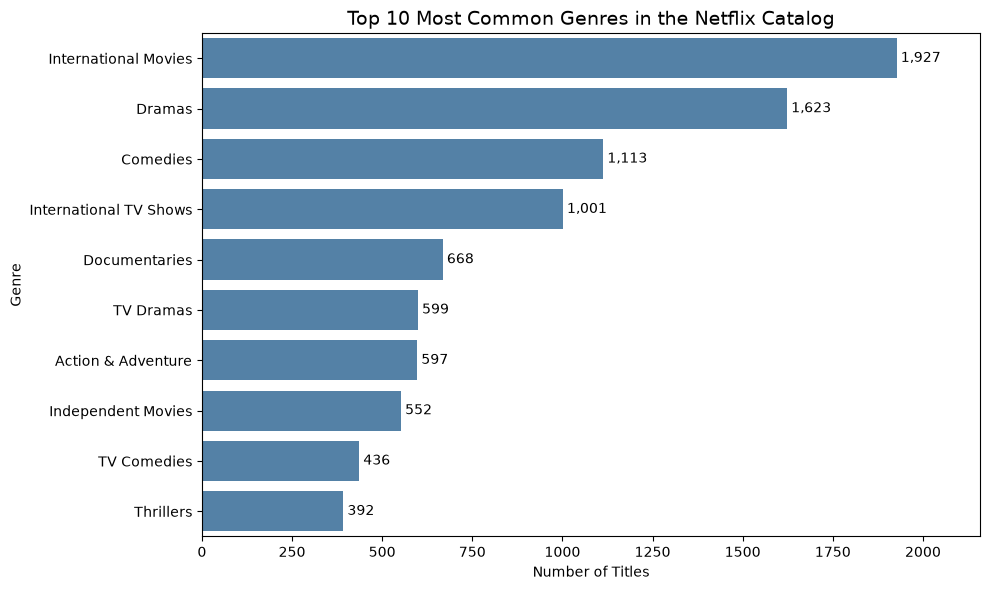

Genre chart saved successfully: outputs\most_common_genres_python.png
Genre chart exists: True


In [21]:
# Create the chart area
plt.figure(figsize=(10, 6))

# Draw the horizontal bars
genre_chart = sns.barplot(
    data=top_genres_data,
    x="Title Count",
    y="Genre",
    color="steelblue"
)

# Add comma-formatted count labels to the bars
for container in genre_chart.containers:
    labels = [
        f"{value:,.0f}"
        for value in container.datavalues
    ]

    genre_chart.bar_label(
        container,
        labels=labels,
        padding=3
    )

# Add room for the count labels
largest_genre_count = top_genres_data["Title Count"].max()

genre_chart.set_xlim(
    0,
    largest_genre_count * 1.12
)

# Add the chart title and axis labels
plt.title(
    "Top 10 Most Common Genres in the Netflix Catalog",
    fontsize=14
)

plt.xlabel("Number of Titles")
plt.ylabel("Genre")

# Adjust the chart layout
plt.tight_layout()

# Save the completed chart before displaying it
plt.savefig(
    genre_chart_file,
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

# Confirm that the image file was created
print(
    f"Genre chart saved successfully: "
    f"{genre_chart_file}"
)

print(
    f"Genre chart exists: "
    f"{genre_chart_file.exists()}"
)

**Finding:**
International Movies is the most common catalog genre with 1,927 title associations, followed by Dramas with 1,623 and Comedies with 1,113. These results measure catalog frequency rather than actual audience viewing because the dataset does not contain watch counts or viewing hours.

# Visualize the Ratings Distribution
A vertical bar chart displays the number of Netflix titles in each content-rating category.

In [22]:
# Convert the rating counts into a DataFrame
rating_data = rating_counts.reset_index()

# Give the columns clear names
rating_data.columns = [
    "Rating",
    "Title Count"
]

# Ensure the title counts are numeric
rating_data["Title Count"] = pd.to_numeric(
    rating_data["Title Count"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

# Arrange the ratings from highest to lowest count
rating_data = rating_data.sort_values(
    by="Title Count",
    ascending=False
)

# Display the chart-ready ratings data
rating_data

,Rating,Title Count
0,TV-MA,2027
1,TV-14,1698
2,TV-PG,701
3,R,508
4,PG-13,286
5,NR,218
6,PG,184
7,TV-Y7,169
8,TV-G,149
9,TV-Y,143


In [23]:
# Define the ratings chart filename
ratings_chart_file = (
    output_folder
    / "ratings_distribution_python.png"
)

print(f"Ratings chart file: {ratings_chart_file}")

Ratings chart file: outputs\ratings_distribution_python.png


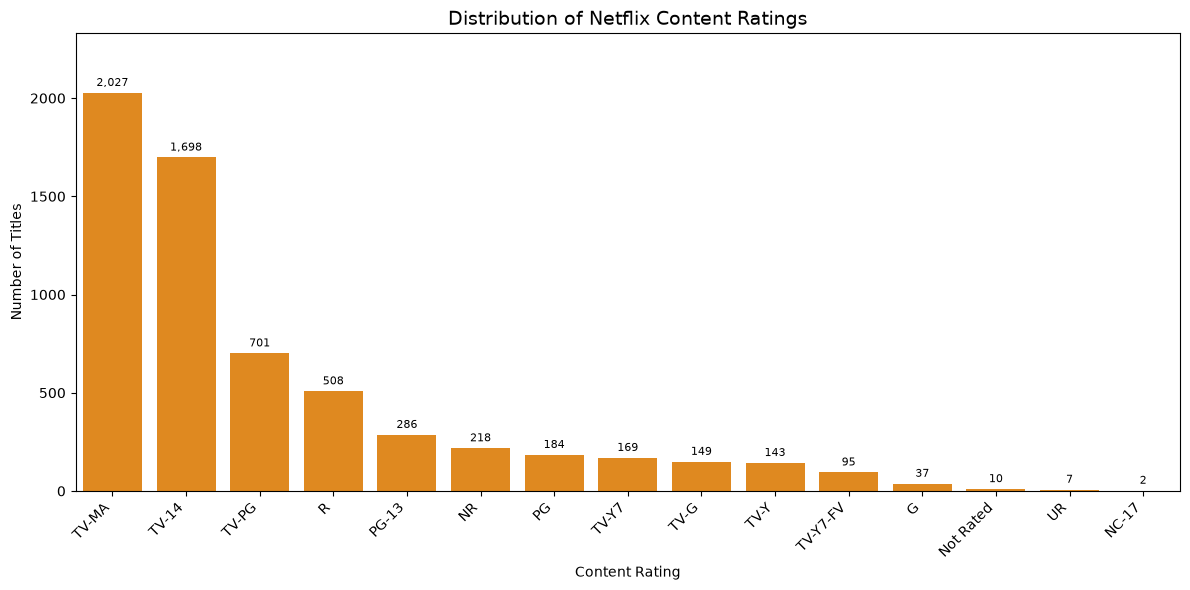

Ratings chart saved successfully: outputs\ratings_distribution_python.png
Ratings chart exists: True


In [24]:
# Create the chart area
plt.figure(figsize=(12, 6))

# Draw the vertical bars
ratings_chart = sns.barplot(
    data=rating_data,
    x="Rating",
    y="Title Count",
    color="darkorange"
)

# Add comma-formatted count labels
for container in ratings_chart.containers:
    labels = [
        f"{value:,.0f}"
        for value in container.datavalues
    ]

    ratings_chart.bar_label(
        container,
        labels=labels,
        padding=3,
        fontsize=8
    )

# Add extra space above the tallest bar
largest_rating_count = (
    rating_data["Title Count"].max()
)

ratings_chart.set_ylim(
    0,
    largest_rating_count * 1.15
)

# Add the title and axis labels
plt.title(
    "Distribution of Netflix Content Ratings",
    fontsize=14
)

plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")

# Rotate the rating labels for readability
plt.xticks(
    rotation=45,
    ha="right"
)

# Adjust the chart layout
plt.tight_layout()

# Save the chart before displaying it
plt.savefig(
    ratings_chart_file,
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

# Confirm that the image was created
print(
    f"Ratings chart saved successfully: "
    f"{ratings_chart_file}"
)

print(
    f"Ratings chart exists: "
    f"{ratings_chart_file.exists()}"
)

**Finding:**
TV-MA is the most common content rating with 2,027 titles, followed by TV-14 with 1,698 titles. Together, these categories account for a substantial share of the catalog, indicating a strong concentration of content classified for mature and teenage audiences.

# Export the Cleaned Data
The cleaned Netflix dataset is exported for reuse in Python and R without changing the original source file.

In [25]:
# Define the cleaned dataset filename
cleaned_data_file = Path(
    "Netflix_shows_movies_cleaned.csv"
)

try:
    # Export the cleaned dataset without a pandas index
    netflix_clean.to_csv(
        cleaned_data_file,
        index=False
    )

    # Confirm that the cleaned CSV was created
    print("Cleaned dataset exported successfully.")
    print(f"Cleaned file: {cleaned_data_file}")
    print(
        f"Cleaned file exists: "
        f"{cleaned_data_file.exists()}"
    )

except PermissionError:
    print(
        "Permission denied. Close the CSV file "
        "if it is currently open and try again."
    )

except OSError as error:
    print(f"File export error: {error}")

except Exception as error:
    print(f"An unexpected error occurred: {error}")

Cleaned dataset exported successfully.
Cleaned file: Netflix_shows_movies_cleaned.csv
Cleaned file exists: True


In [26]:
# Reload the exported cleaned dataset
verified_cleaned_data = pd.read_csv(
    cleaned_data_file
)

# Display the exported dataset dimensions
print(
    f"Verified rows: "
    f"{verified_cleaned_data.shape[0]:,}"
)

print(
    f"Verified columns: "
    f"{verified_cleaned_data.shape[1]}"
)

# Check the cleaned text columns
verified_text_columns = [
    "director",
    "cast",
    "country",
    "rating"
]

verified_missing_values = (
    verified_cleaned_data[verified_text_columns]
    .isna()
    .sum()
)

print("\nMissing text values in exported dataset:")
print(verified_missing_values)

Verified rows: 6,234
Verified columns: 12

Missing text values in exported dataset:
director    0
cast        0
country     0
rating      0
dtype: int64


# Verify Python and R Results
The Python rating counts are exported so they can be compared with the counts produced independently in R.

In [27]:
# Define the rating-summary file
rating_counts_file = Path("rating_counts_python.csv")

# Export the Python rating counts
rating_data.to_csv(
    rating_counts_file,
    index=False
)

# Confirm that the file was created
print("Python rating counts exported successfully.")
print(f"Rating-count file: {rating_counts_file}")
print(
    f"Rating-count file exists: "
    f"{rating_counts_file.exists()}"
)

Python rating counts exported successfully.
Rating-count file: rating_counts_python.csv
Rating-count file exists: True


## Findings and Limitations
The dataset contains 6,234 Netflix titles, including 4,265 Movies and 1,969 TV Shows. Movies represent 68.4% of the catalog, while TV Shows account for 31.6%.

International Movies is the most frequent genre with 1,927 title associations, followed by Dramas with 1,623 and Comedies with 1,113. TV-MA is the most common content rating with 2,027 titles, followed by TV-14 with 1,698.

The dataset does not contain watch counts, viewing hours, or audience totals. Therefore, genre frequency in the Netflix catalog was used as a proxy for the assignment's “most watched genres” requirement.

Missing text values were replaced with descriptive labels, while 11 unavailable date_added values were retained as missing dates instead of being replaced with invented information. The Python and R rating counts were compared and produced identical results.